# RISE second-life BESS (Conbat)

This notebook lists the released modules, loads one module in one collection window, and plots its voltage. It makes no diagnosis.

## 1. Released units

This step lists what `systems('rise_conbat')` reports for the release.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'fielddata').exists())
sys.path.insert(0, str(ROOT))
from fielddata import load, systems

released = systems('rise_conbat')
display(released)

,unit,id,car,car_model,installations,first_start,last_end
0,S370751-1,S370751-1,S370751,VW Passat 20-,1,2022-12-31 23:00:00+00:00,2023-04-25 22:00:00+00:00
1,S371657-1,S371657-1,S371657,VW Passat 15-,1,2023-04-25 22:00:00+00:00,2023-08-15 16:00:00+00:00
2,H403787-1,H403787-1,H403787,VW Passat 15-,1,2023-08-15 16:00:00+00:00,2023-11-27 00:00:00+00:00
3,H406450-1,H406450-1,H406450,VW Passat 15-,1,2023-11-27 00:00:00+00:00,NaT
4,S370751-2,S370751-2,S370751,VW Passat 20-,1,2022-12-31 23:00:00+00:00,2023-04-25 22:00:00+00:00
...,...,...,...,...,...,...,...
83,H410124-7,H410124-7,H410124,VW Passat 15-,1,2023-04-19 22:00:00+00:00,2023-08-15 16:00:00+00:00
84,W37824-7,W37824-7,W37824,VW Passat 15-,2,2023-08-15 16:00:00+00:00,NaT
85,W103457-8,W103457-8,W103457,VW Passat 15-,1,2022-12-31 23:00:00+00:00,2023-04-19 22:00:00+00:00
86,H410124-8,H410124-8,H410124,VW Passat 15-,1,2023-04-19 22:00:00+00:00,2023-08-15 16:00:00+00:00


Each row is one distinct module id with its car, model and installations. Modules were swapped through the same positions over time.

## 2. One unit as released

This step loads one unit with the default `clean=False`, so every value is as released.

In [2]:
frame = load('rise_conbat', window='9. 240210-240215', level='module', unit='H400788-1')
print(frame.shape)
display(frame.head())

(8640, 10)


,hour,module_uuid,location,rack,shelf,module,voltage,voltage_is_filler,temperature,temperature_is_filler
0,2024-02-10 00:00:00+00,H400788-1,3,1,2,1,49.801598,f,22.126194,f
1,2024-02-10 00:01:00+00,H400788-1,3,1,2,1,49.764000,f,22.043013,f
2,2024-02-10 00:02:00+00,H400788-1,3,1,2,1,49.556404,f,22.117317,f
3,2024-02-10 00:03:00+00,H400788-1,3,1,2,1,49.466003,f,22.130812,f
4,2024-02-10 00:04:00+00,H400788-1,3,1,2,1,49.384804,f,22.105824,f


One module over the window 10 to 15 February 2024, one row per minute, with filler flags as released.

## 3. Signal ranges

This step summarises a few signals of the loaded unit.

In [3]:
display(frame[['voltage', 'temperature']].describe().T)

,count,mean,std,min,25%,50%,75%,max
voltage,8640.0,44.743844,3.796759,37.550400,42.444100,44.441600,48.210001,50.144398
temperature,8640.0,24.266211,0.910921,22.043013,23.688859,24.152782,24.715618,27.464827


These ranges are raw values as released, before any cleaning. The schema file next to the loader lists units and any sentinel codes.

## 4. A first look

This step plots one signal to show the shape of the data.

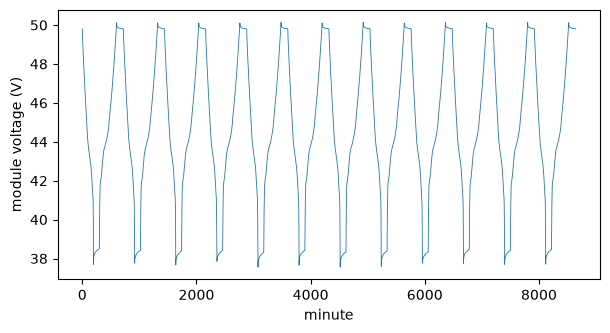

In [4]:
ax = frame['voltage'].plot(figsize=(7, 3.5), lw=0.6)
ax.set_xlabel('minute')
ax.set_ylabel('module voltage (V)')
plt.show()

Over the window the module voltage ranges from 37.6 to 50.1 V and its temperature from 22.0 to 27.5 degC. Values are raw, as released.